In [1]:
import numpy as np

import matplotlib.pyplot as plt



##### read and preprocess for training and test
train_loaded = np.load('dataSVO.npz')
nwarmup_all = train_loaded['nwarupsteps']
real_sigma_all = train_loaded['realpart_sigma']
img_sigma_all = train_loaded['imgpart_sigma']

real_g0_all = train_loaded['realpart_g0']
img_g0_all = train_loaded['imgpart_g0']



unique_nwarmups = np.unique(nwarmup_all)
nwarmups_train = unique_nwarmups[::4]


mask_train = np.isin(nwarmup_all, nwarmups_train)
mask_test = ~np.isin(nwarmup_all, nwarmups_train)

nwarmups_test = np.unique(nwarmup_all[mask_test])

print('train', len(nwarmups_train))
print('test', len(nwarmups_test))

train 8
test 22


In [2]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Lambda, Embedding, BatchNormalization,LSTM, RepeatVector, TimeDistributed, concatenate, Reshape
from tensorflow.keras.losses import mse, binary_crossentropy
from tensorflow.keras import backend as K
import random

2025-06-25 17:16:37.948771: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-06-25 17:16:37.958160: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1750864597.969389    7384 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1750864597.972772    7384 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1750864597.981410    7384 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

In [3]:

# Define the model
latent_dim = 64

sequence_length = img_sigma_all.shape[1]
print(sequence_length)



# Set seeds for reproducibility
seed_value = 100
np.random.seed(seed_value)
random.seed(seed_value)
tf.random.set_seed(seed_value)




# Encoder


# Encoder
encoder_inputs = Input(shape=(sequence_length, 1))
label_inputs = Input(shape=(1,))  # Label input for the embedding
label_inputs_repeated = RepeatVector(sequence_length)(label_inputs)




# Concatenate the time series input with the embedded categorical input
merged_inputs = concatenate([encoder_inputs,label_inputs_repeated],axis=-1)

encoder_lstm = LSTM(latent_dim, return_state=True)
encoder_outputs, state_h, state_c = encoder_lstm(merged_inputs)
encoder_states = [state_h, state_c]

# Decoder
decoder_inputs = RepeatVector(sequence_length)(encoder_outputs)
decoder_lstm = LSTM(latent_dim, return_sequences=True)
decoder_outputs = decoder_lstm(decoder_inputs, initial_state=encoder_states)
decoder_dense = TimeDistributed(Dense(1))
decoder_outputs = decoder_dense(decoder_outputs)

# Define the full model
model = Model(inputs=[encoder_inputs, label_inputs], outputs=decoder_outputs)

# Compile the model
model.compile(optimizer='adam', loss='mse')

# Summary of the model
model.summary()
for layer in model.layers:
    print(layer.name)

64


2025-06-25 17:16:47.723616: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer         │ (None, 64, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 64, 1)     │          0 │ input_layer_1[0]… │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 2)     │          0 │ input_layer[0][0… │
│ (Concatenate)       │                   │            │ repeat_vector[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ [(None, 64),      │     17,152 │ concatenate[0][0] │
│                     │ (None, 64),       │            │                   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector_1     │ (None, 64, 64)    │          0 │ lstm[0][0]        │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 64, 64)    │     33,024 │ repeat_vector_1[… │
│                     │                   │            │ lstm[0][1],       │
│                     │                   │            │ lstm[0][2]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed    │ (None, 64, 1)     │         65 │ lstm_1[0][0]      │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 50,241 (196.25 KB)

 Trainable params: 50,241 (196.25 KB)

 Non-trainable params: 0 (0.00 B)

input_layer_1
input_layer
repeat_vector
concatenate
lstm
repeat_vector_1
lstm_1
time_distributed


In [4]:
#### train data
from sklearn.preprocessing import StandardScaler,MinMaxScaler, PowerTransformer
import joblib
'''
print(np.max(nwarmup_all,axis=0), np.min(nwarmup_all,axis=0))
scaler_x = PowerTransformer(method='box-cox')
scaler_y = PowerTransformer(method='box-cox')

'''
min_max_normal = lambda x: (x-min(x)/(max(x) - min(x)))
print(max(nwarmup_all), min(nwarmup_all))
all_labels = min_max_normal(nwarmup_all) #nwarmup

train_labels = all_labels[mask_train]
test_labels = all_labels[mask_test]

### preprocess

X_all = img_g0_all #min_max_normal(img_train)
Y_all = img_sigma_all

X_train = X_all[mask_train]
X_test = X_all[mask_test]
X_train_scaled = X_train.reshape(-1,sequence_length , 1)
X_test_scaled = X_test.reshape(-1,sequence_length , 1)


Y_train = Y_all[mask_train]
Y_test = Y_all[mask_test]
Y_train_scaled = Y_train.reshape(-1,sequence_length , 1)
Y_test_scaled = Y_test.reshape(-1,sequence_length , 1)



580000 50000


In [5]:
# Train VAE
num_epochs = 40
batch_size = 128

history = model.fit([X_train_scaled,train_labels],Y_train_scaled,epochs=num_epochs, batch_size=batch_size,validation_split=0.2)


Epoch 1/40


2025-06-25 17:17:03.382738: E tensorflow/core/util/util.cc:131] oneDNN supports DT_INT32 only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 164ms/step - loss: 0.0965 - val_loss: 0.0315
Epoch 2/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0217 - val_loss: 0.0075
Epoch 3/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - loss: 0.0060 - val_loss: 0.0034
Epoch 4/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - loss: 0.0040 - val_loss: 0.0020
Epoch 5/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 103ms/step - loss: 0.0021 - val_loss: 0.0014
Epoch 6/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - loss: 0.0014 - val_loss: 0.0010
Epoch 7/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 8.2445e-04 - val_loss: 5.8189e-04
Epoch 8/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step - loss: 5.3020e-04 - val_loss: 3.6214e-04
Epoch 9/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - loss: 3.4750e-04 - val_loss: 2.8617e-04
Epoch 10/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 103ms/step - loss: 2.5495e-04 - val_loss: 1.8061e-04
Epoch 11/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 1.7211e-04 - val_loss: 1.4088e-04
Epoch 12/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/

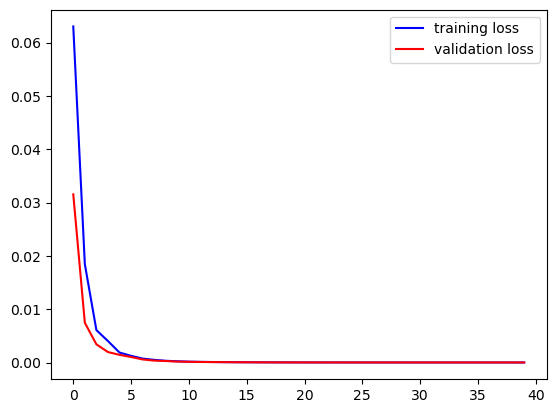

In [6]:
#### plot loss
plt.plot(history.history['loss'],'b-',label='training loss')
plt.plot(history.history['val_loss'],'r-',label='validation loss')
plt.legend()
plt.show()

In [7]:
y_pred =model.predict([X_test_scaled,test_labels])

104/104 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step


In [8]:
model.save('trained_model_svo_dataless.keras')

In [9]:
print(y_pred.shape)

(3300, 64, 1)


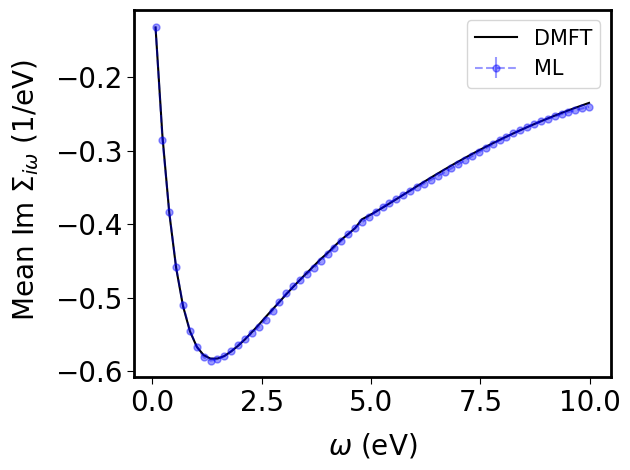

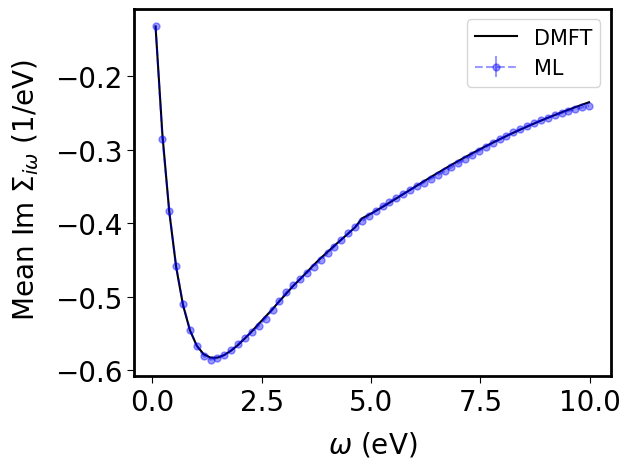

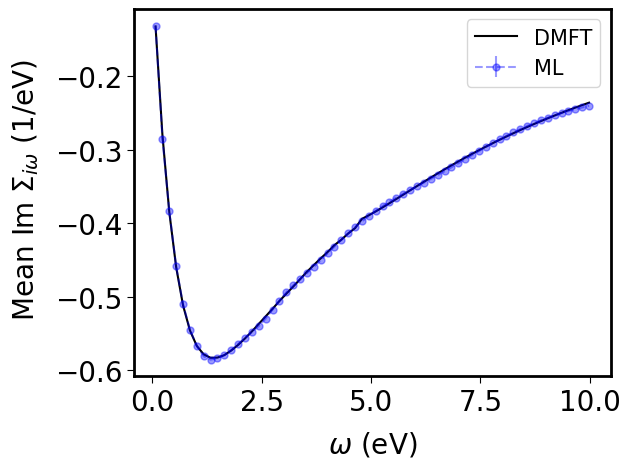

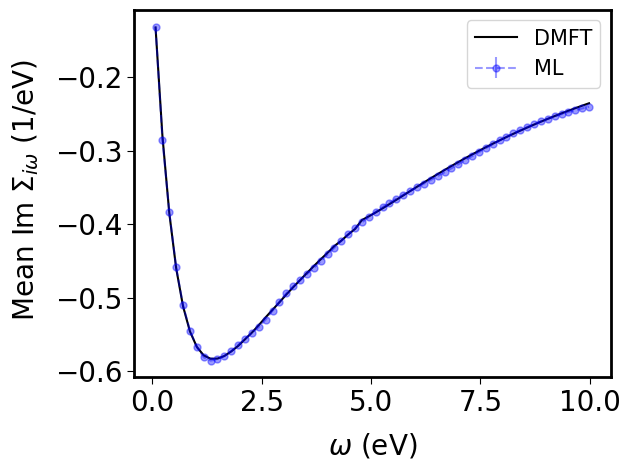

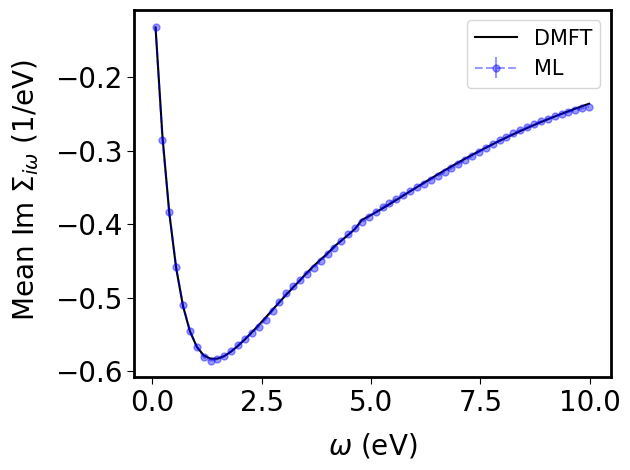

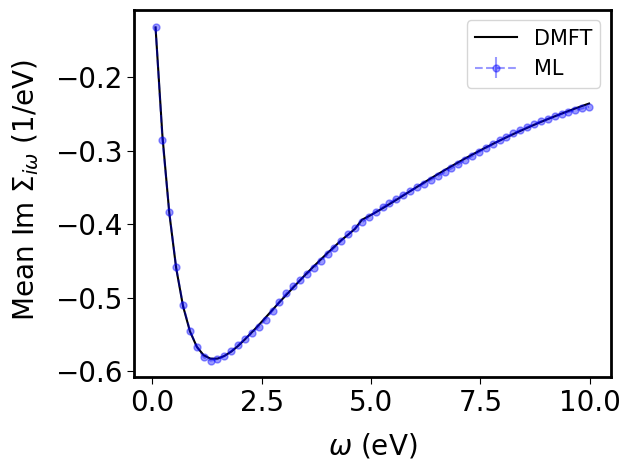

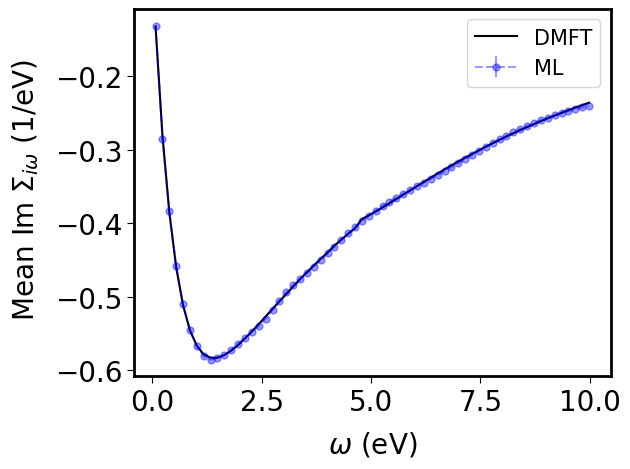

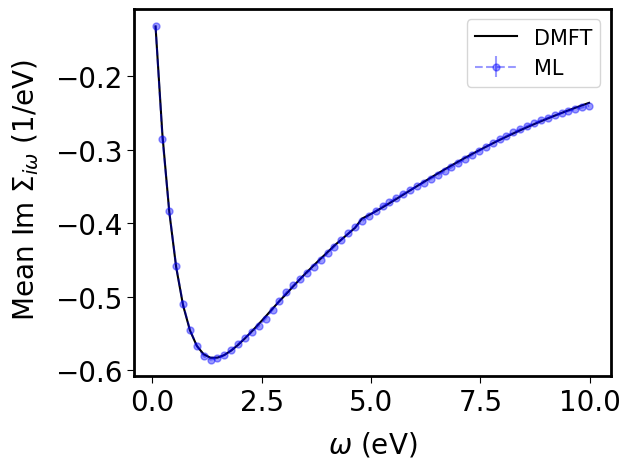

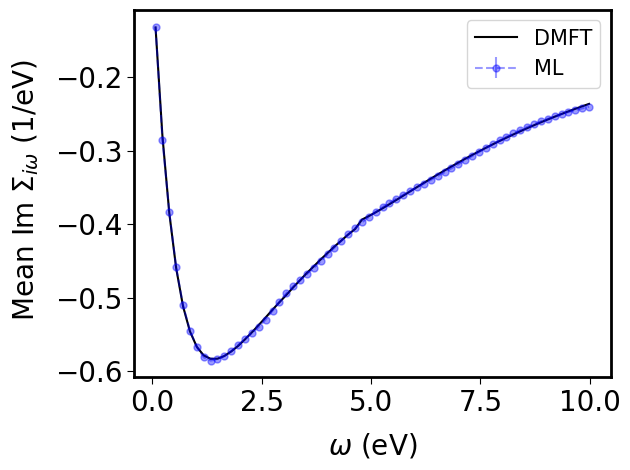

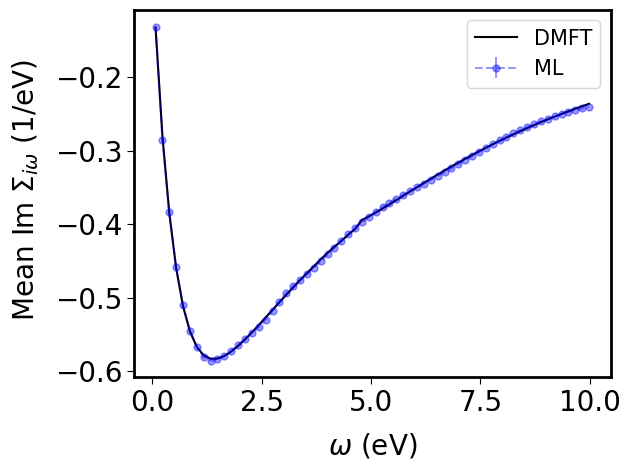

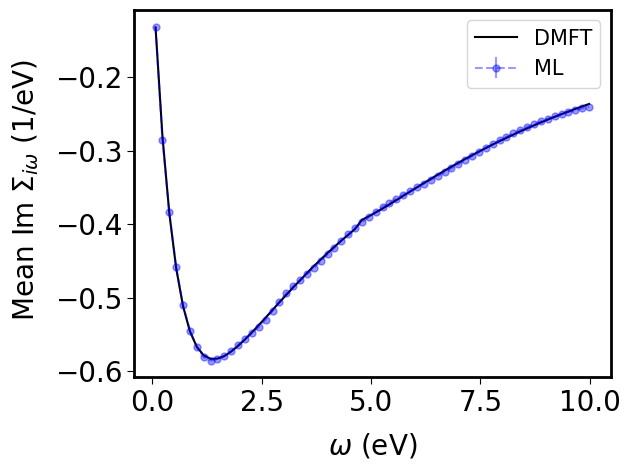

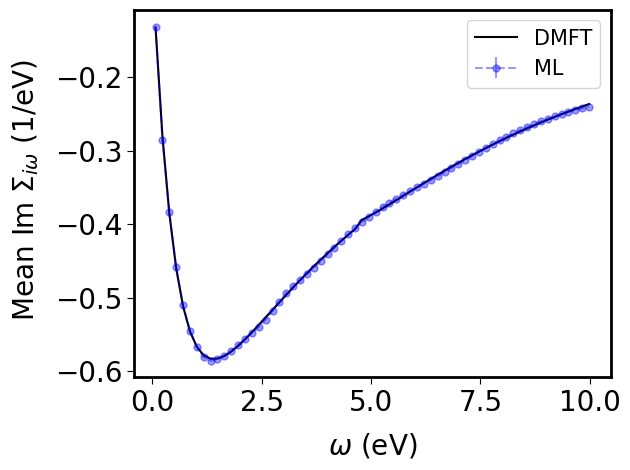

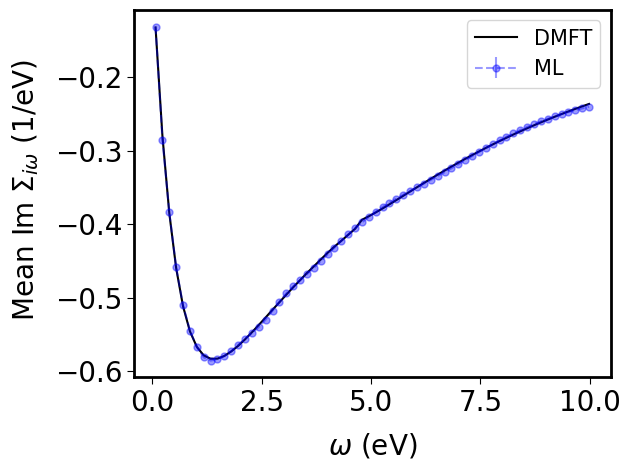

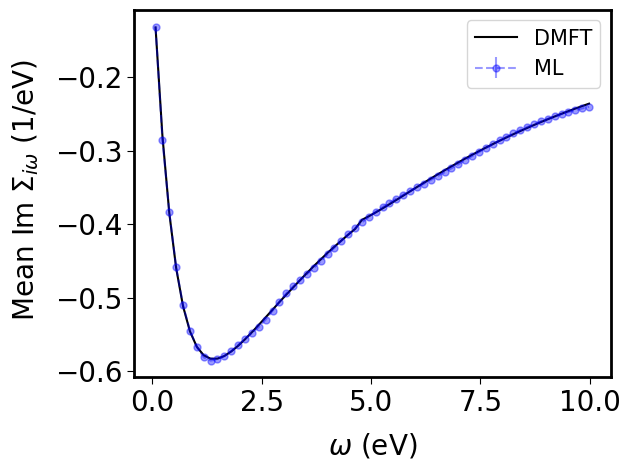

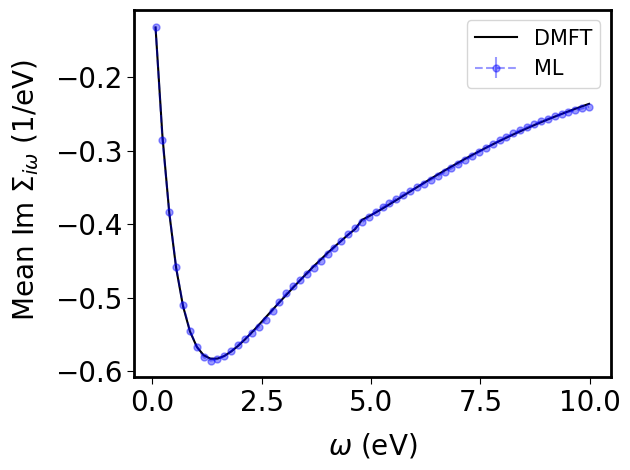

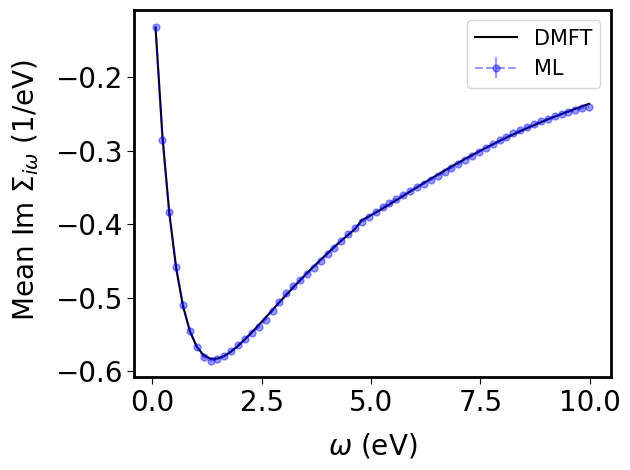

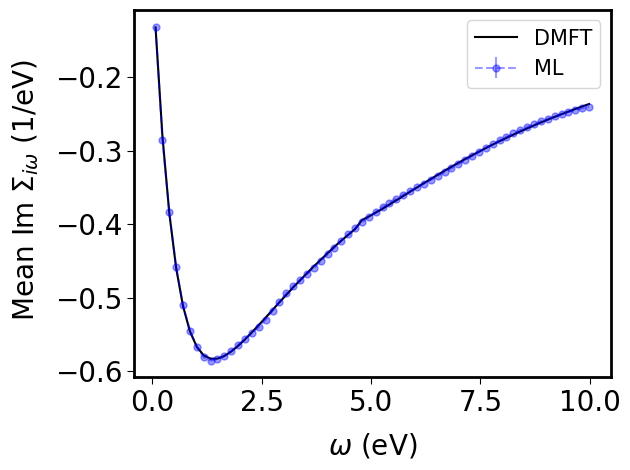

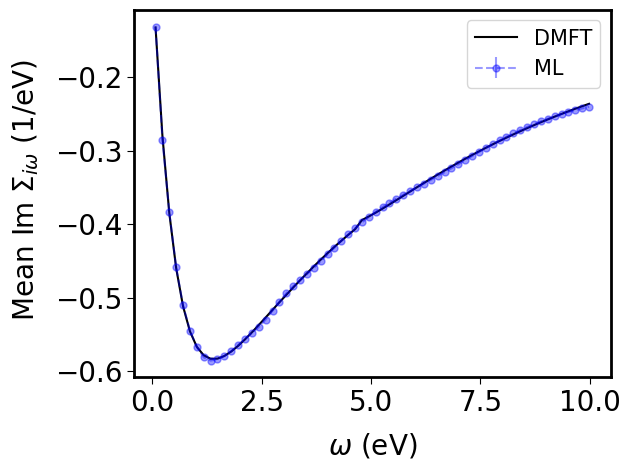

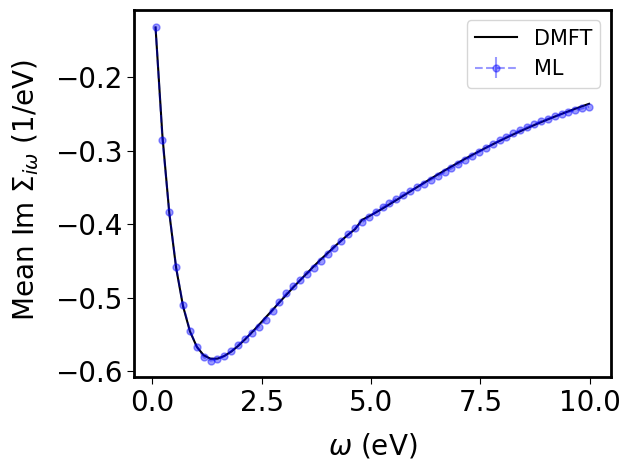

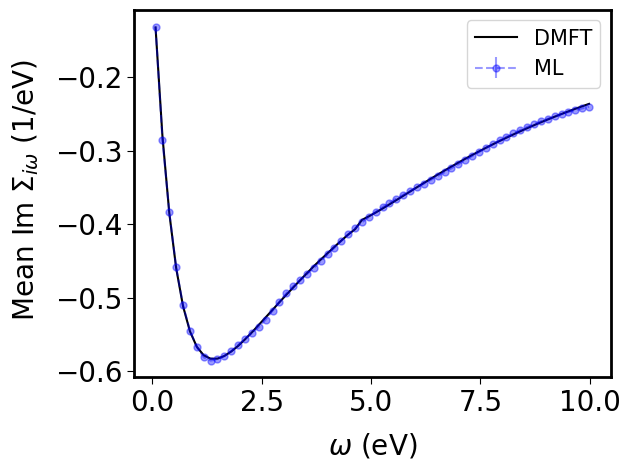

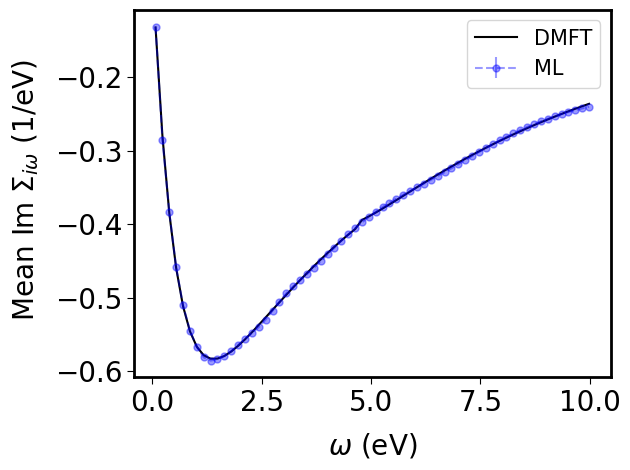

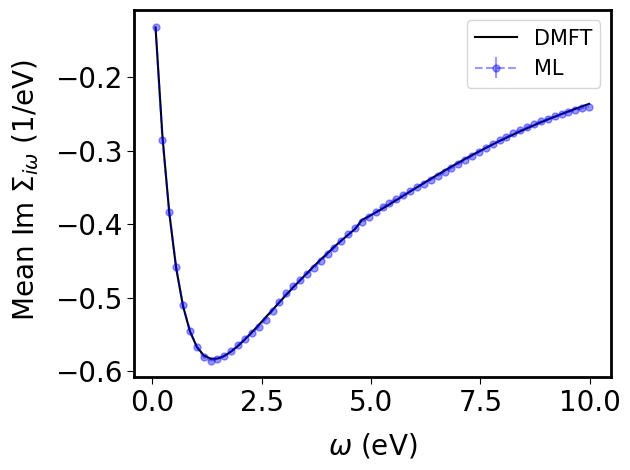

In [11]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica'],
    'font.size': 10,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 10,
    'axes.linewidth': 2.0,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'xtick.minor.width': 0.6,
    'ytick.minor.width': 0.6,
    'xtick.major.size': 5,
    'ytick.major.size': 5,
    'xtick.minor.size': 3,
    'ytick.minor.size': 3,
    'axes.labelpad': 10
})







y_test = Y_test_scaled

nwarmup_labels = nwarmup_all[mask_test]
unique_labels = np.unique(nwarmup_labels)

### frequency
freq=np.linspace(-161,161,2050)
mask = (freq > 0) & (freq < 10)
freq_sel = freq[mask]
rms = lambda x: np.sqrt(np.mean(x*x))

rms_mean =[]
y_truth_all=[]
y_pred_all=[]
y_pred_std_all=[]

#### plot truth vs prediction avg plot for each unique warmup step
#### plot truth vs prediction avg plot for each unique warmup step
for i in np.arange(len(unique_labels)):
    y_pred_mean = np.mean(y_pred[nwarmup_labels==unique_labels[i]],axis=0)
    y_truth_mean =  np.mean(y_test[nwarmup_labels==unique_labels[i]],axis=0)
    #rms_mean.append(rms(y_pred_mean-y_truth_mean))
    rms_mean.append(rms((y_pred_mean.flatten()-y_truth_mean.flatten()) / y_truth_mean.flatten()))

    y_pred_std = np.std(y_pred[nwarmup_labels==unique_labels[i]],axis=0)
    plt.errorbar(freq_sel,y_pred_mean.flatten(),yerr=y_pred_std.flatten(), ls='--', marker='o',color='blue',markersize=5,alpha=0.4,label='ML')
    #plt.title(f'Nwarmup step:{unique_labels[i]}',fontsize=20)
    #plt.plot(freq_sel,y_pred_mean,'b.-',label='prediction')
    plt.plot(freq_sel,y_truth_mean,'k-',label='DMFT')
    plt.ylabel(r' Mean Im $\Sigma_{i\omega}$ (1/eV)', fontsize=20)
    plt.xlabel('$\omega$ (eV)',fontsize=20)
    plt.legend(fontsize=15)
    plt.tight_layout()
    plt.savefig(f'new_plots/SVO_prediction_onefourth_{unique_labels[i]}.png')
    plt.show()

    y_truth_all.append(y_truth_mean)
    y_pred_all.append(y_pred_mean)
    y_pred_std_all.append(y_pred_std)










In [ ]:
for i in range(20):
    print('nwarmup step', nwarmup_labels[i])
    plt.plot(y_pred[i],'b.-')
    plt.plot(y_test[i],'k-')
    plt.ylabel('Sigma_iw', fontsize=20)
    plt.title(f'Nwarmup step:{nwarmup_labels[i]}',fontsize=20)
    plt.tight_layout()
    #plt.savefig(f'new_plots/g02iw_{nwarmup_labels[i]}.png')
plt.show()

In [12]:
np.save('mean_rms_onefourth.npy',np.array([unique_labels,rms_mean]))
np.savez('onefourth_data', unique_labels=unique_labels,y_truth_all=y_truth_all,y_pred_all=y_pred_all,y_pred_std_all=y_pred_std_all)

In [ ]:
'''
x = np.load('rms_diff_onethird_traindata.npy')
y = np.load('rms_diff_onefourth_traindata.npy')
plt.figure(figsize=(9,6))
fig, (ax1, ax2) = plt.subplots( 2)
#fig.suptitle('Horizontally stacked subplots')
ax1.plot(x[0],x[1],'r.',label='train data 1/3')
ax1.legend(fontsize=12)
ax2.plot(y[0],y[1],'g*',label='train data 1/4')
ax2.legend(fontsize=12)
ax2.set_xlabel('Nwarmupsteps', fontsize=15)
ax1.set_ylabel('Rms of residual', fontsize=15)
plt.show()
'''

In [ ]:
#train_1/3 [ 50000  80000 120000 180000 240000 300000 360000 420000 480000 540000]
#train_1/4: train [ 50000 100000 200000 300000 400000 500000]